<a href="https://colab.research.google.com/github/FadhilTaufiqurrachman/Machine-Learning/blob/main/244107020090_Fadhil_Taufiqurrachman_T7.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Tugas Praktikum Jobsheet 7

NIM : 244107020090

Nama : Fadhil Taufiqurrachman

Kelas : TI 3G

No Absen : 06

Mata Kuliah : Pembelajaran Mesin

Persiapan Data

In [ ]:
# Mount Google Drive
from google.colab import drive
drive.mount('/content/drive')
BASE_PATH = '/content/drive/MyDrive/Education/Current Semester College File /Machine Learning/'

Mounted at /content/drive


Import Library

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

1. Identifikasi Variable dan Membaca Dataset.

In [ ]:
df = pd.read_csv(BASE_PATH + 'insurance.csv')

# Menampilkan data awal dan struktur dataset
print("Data Awal:")
display(df.head())

print("\nInformasi Data:")
df.info()

Data Awal:


,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520



Informasi Data:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   object 
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   object 
 5   region    1338 non-null   object 
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), object(3)
memory usage: 73.3+ KB


Dataset insurance.csv (Medical Cost Personal Datasets) berisi informasi tagihan biaya asuransi kesehatan pasien berdasarkan atribut pribadi mereka. Variabel yang relevan meliputi:

- age: Usia penerima asuransi (numerik).

- sex: Jenis kelamin, pria atau wanita (kategorikal).

- bmi: Body Mass Index, mengukur berat badan ideal (numerik).

- children: Jumlah anak/tanggungan yang dicakup asuransi (numerik).

- smoker: Status merokok pasien (kategorikal).

- region: Wilayah domisili di AS (kategorikal).

- charges: Biaya medis yang ditagihkan. Ini adalah variabel target (y) yang akan kita prediksi.

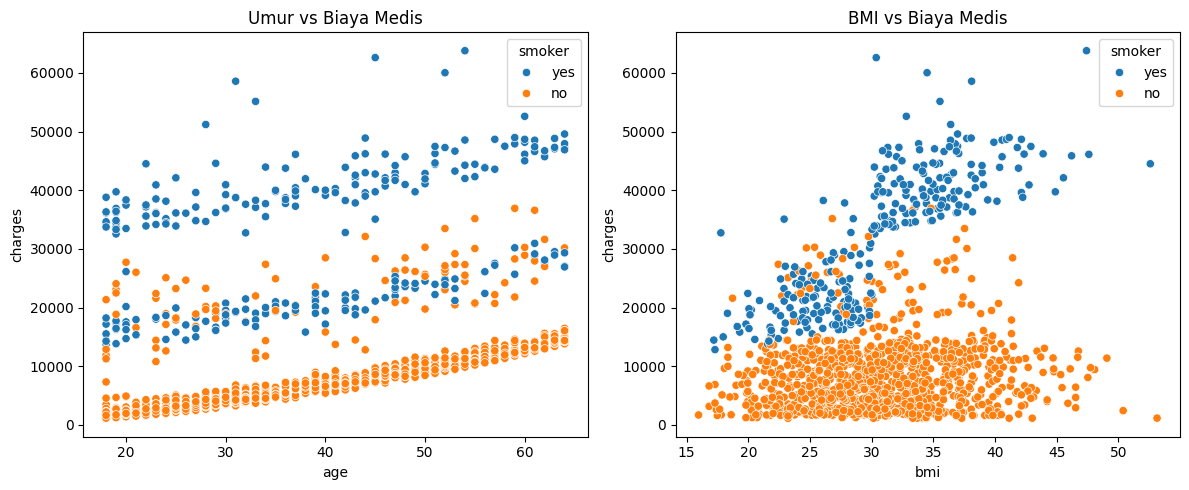


Data setelah diubah ke bentuk numerik (One-Hot Encoding):


,age,bmi,children,charges,sex_male,smoker_yes,region_northwest,region_southeast,region_southwest
0,19,27.900,0,16884.92400,False,True,False,False,True
1,18,33.770,1,1725.55230,True,False,False,True,False
2,28,33.000,3,4449.46200,True,False,False,True,False
3,33,22.705,0,21984.47061,True,False,True,False,False
4,32,28.880,0,3866.85520,True,False,True,False,False


In [ ]:
# Visualisasi Data (Scatter Plot)
# Melihat pengaruh Umur dan BMI terhadap Biaya Medis, dibedakan oleh status merokok
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
sns.scatterplot(x='age', y='charges', hue='smoker', data=df)
plt.title('Umur vs Biaya Medis')

plt.subplot(1, 2, 2)
sns.scatterplot(x='bmi', y='charges', hue='smoker', data=df)
plt.title('BMI vs Biaya Medis')

plt.tight_layout()
plt.show()

# Preprocessing: One-Hot Encoding untuk variabel teks/kategorikal
# drop_first=True digunakan untuk menghindari jebakan multikolinearitas (dummy variable trap)
df_encoded = pd.get_dummies(df, drop_first=True)

print("\nData setelah diubah ke bentuk numerik (One-Hot Encoding):")
display(df_encoded.head())

2. Pembagian Dataset Menjadi Data Train dan Data Test.

In [ ]:
# Identifikasi fitur (X) dan target (y)
X = df_encoded.drop('charges', axis=1) # Mengambil seluruh kolom kecuali 'charges'
y = df_encoded['charges']              # Mengambil hanya kolom 'charges'

# Membagi dataset menjadi data latih (80%) dan data uji (20%)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

3. Melakukan Feature Scaling

In [ ]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

4. Membuat Model Multiple Linear Regression Menggunakan Scikit-Learn.

In [ ]:
# Pembuatan dan pelatihan model Multiple Linear Regression
mlr_model = LinearRegression()

5. Melatih Model pada Data Latih dan Melakukan Prediksi pada Data Uji

In [ ]:
mlr_model.fit(X_train_scaled, y_train)

# Melakukan prediksi menggunakan data uji
y_pred = mlr_model.predict(X_test_scaled)

6. Evaluasi Model

In [ ]:
# Evaluasi model dengan menghitung metrik
r2 = r2_score(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)

# Menampilkan hasil evaluasi
print("Hasil Evaluasi Model Multiple Linear Regression:")
print(f"R-squared : {r2:.4f}")
print(f"MSE       : {mse:.4f}")
print(f"MAE       : {mae:.4f}")

Hasil Evaluasi Model Multiple Linear Regression:
R-squared : 0.7836
MSE       : 33596915.8514
MAE       : 4181.1945


7. Visualisasi Hasil

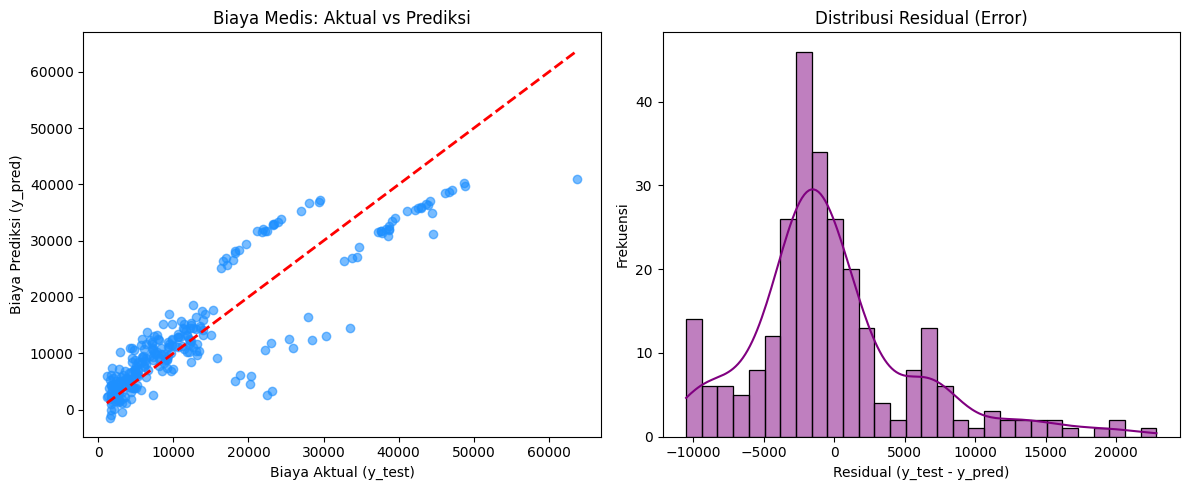

In [ ]:
# 1. Scatter Plot: Nilai Aktual vs Nilai Prediksi
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.scatter(y_test, y_pred, alpha=0.6, color='dodgerblue')
# Membuat garis referensi ideal (y = x) berwarna merah putus-putus
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2)
plt.title('Biaya Medis: Aktual vs Prediksi')
plt.xlabel('Biaya Aktual (y_test)')
plt.ylabel('Biaya Prediksi (y_pred)')

# 2. Histogram Distribusi Residual (Error)
residuals = y_test - y_pred

plt.subplot(1, 2, 2)
sns.histplot(residuals, bins=30, kde=True, color='purple')
plt.title('Distribusi Residual (Error)')
plt.xlabel('Residual (y_test - y_pred)')
plt.ylabel('Frekuensi')

plt.tight_layout()
plt.show()

Berdasarkan hasil eksekusi Multiple Linear Regression, model terbukti bekerja dengan cukup baik, menghasilkan nilai akurasi R-squared sekitar 0.7836. Hal ini mengindikasikan bahwa sekitar 78.36% variasi atau perubahan dari biaya asuransi medis (charges) dapat dijelaskan dengan sangat baik oleh kombinasi atribut pasien (usia, BMI, anak, jenis kelamin, domisili, dan status merokok). Melalui visualisasi scatter plot yang dilakukan sebelumnya, dapat dilihat dengan sangat jelas bahwa variabel status perokok merupakan faktor penentu paling dominan yang menyebabkan pembengkakan biaya asuransi; kelompok pasien perokok memiliki garis tren tagihan yang jauh terpisah (lebih tinggi) dibandingkan pasien non-perokok pada rentang usia dan BMI yang sama. Langkah encoding data kategorikal dipadukan dengan feature scaling terbukti krusial di praktikum ini agar algoritma matematis dari Scikit-Learn dapat memproses dan menyeimbangkan bobot semua variabel (seperti membandingkan rentang umur puluhan dan biaya belasan ribu dolar) secara efisien dan akurat tanpa mengalami bias komputasi.